# ¿Subieron los precios de vivienda en Cali después del sismo del 10 de agosto?

Mucha gente dice que, después del sismo, los precios de la vivienda en Cali **se dispararon** y que hubo
quien **se aprovechó para subirlos**. Este notebook lo pone a prueba con los avisos de venta que el
scraper viene recolectando desde antes del sismo.

**Cuatro preguntas:**

1. ¿Los vendedores **subieron el precio de lo que ya tenían publicado**? (el mismo aviso antes y después)
2. ¿Los avisos **nuevos** salen **más caros** que lo que había antes del sismo, comparando inmuebles parecidos?
3. ¿Salió **más oferta** a la venta en Cali?
4. ¿Hay diferencias **por zona, tipo o estrato** dentro de Cali?

Cada resultado de Cali se compara con **ciudades lejanas al sismo** (control). Si Cali cambia igual que
Bogotá o Medellín, lo que se ve es el mercado normal, no el sismo.

**Qué miden estos datos y qué no:**

- Son **precios pedidos** en avisos de venta de FincaRaíz, **no precios de cierre**.
- Son **ventas, no arriendos**. Tras un sismo, lo que más se comenta suele ser el arriendo, y eso no está aquí.
- Los datos de 2026 empiezan el **2 de agosto**: la semana anterior al sismo es la línea base.
  Hay además una foto de **julio de 2025** que sirve para ver la tendencia normal de un año.

In [1]:
import io
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import eventos, master, zonas

# ── Parámetros ──────────────────────────────────────────────────────────────
FECHA_SISMO = "2026-08-10"
CIUDAD = "Cali"
CERCANAS = ["Jamundí", "Palmira", "Yumbo"]          # área metropolitana: pudieron sentirlo también
CONTROLES = ["Bogotá", "Medellín", "Barranquilla", "Cartagena", "Bucaramanga"]   # lejos del sismo
TIPOS = ["Apartamento", "Apartaestudio", "Casa"]
REHACER_PANEL = False                                 # True para releer el historial de git

# ── Estilo de los gráficos ──────────────────────────────────────────────────
COLOR = {"Cali": "#2a78d6", "Cercanas": "#eb6834", "Control": "#a3a29b"}
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA2, "axes.titlecolor": TINTA,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": REJILLA, "grid.linewidth": 0.8, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "font.size": 10.5, "legend.frameon": False,
})
pct = mtick.PercentFormatter(1.0, decimals=0)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 1. Los datos

Cada **observación** es el precio de un aviso en una fecha. Salen de dos fuentes:

- **Julio de 2025**: los CSV sueltos de `data/raw/` (scrapeo del 6–7 de julio de 2025).
- **2026**: todas las fotos diarias del master (en git hasta la migración a R2 y en R2 desde entonces). Cada versión de un aviso trae su
  `fecha_recoleccion`, así que juntas forman la historia de precios desde el 2 de agosto.

Periodos: **Julio 2025** · **Antes** (2 al 9 de agosto de 2026) · **Después** (desde el 11 de agosto).
El día del sismo se excluye. Solo vivienda (apartamento, apartaestudio, casa), sin proyectos sobre planos.

In [2]:
CACHE = ROOT / "data" / "analisis" / "observaciones.parquet"

def construir_panel() -> pd.DataFrame:
    """(id_inmueble, fecha, precio) de cada versión observada de cada aviso."""
    partes = []
    for _, _, contenido in eventos.fotos_master():     # git hasta la migración, R2 después
        try:
            foto = pd.read_parquet(io.BytesIO(contenido),
                                   columns=["id_inmueble", "fecha_recoleccion", "Precio listado"])
        except Exception:          # fotos viejas sin fecha_recoleccion
            continue
        foto = foto.dropna(subset=["fecha_recoleccion"]).astype(str)
        partes.append(foto.assign(fecha=foto["fecha_recoleccion"].str[:10]))
    o26 = pd.concat(partes)

    csvs = sorted((ROOT / "data" / "raw").glob("*.csv"))       # julio 2025
    o25 = pd.concat([pd.read_csv(f, usecols=["URL detalle", "Precio listado"]) for f in csvs])
    o25 = o25[~o25["URL detalle"].astype(str).str.contains("proyectos-vivienda")]
    o25["id_inmueble"] = o25["URL detalle"].astype(str).str.rstrip("/").str.split("/").str[-1]
    o25["fecha"] = "2025-07-07"

    cols = ["id_inmueble", "fecha", "Precio listado"]
    o = pd.concat([o26[cols], o25[cols]]).drop_duplicates(["id_inmueble", "fecha"], keep="last")
    o["precio"] = o["Precio listado"].map(eventos.a_numero)
    return o.dropna(subset=["precio"])[["id_inmueble", "fecha", "precio"]]

if REHACER_PANEL or not CACHE.exists():
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    construir_panel().to_parquet(CACHE, index=False)
obs = pd.read_parquet(CACHE)
print(f"{len(obs):,} observaciones de {obs['id_inmueble'].nunique():,} avisos")

853,064 observaciones de 187,269 avisos


In [3]:
# Atributos fijos de cada aviso (tipo, área, estrato, zona…). Se incluyen los avisos
# históricos de julio de 2025, que el dataset de la app excluye por no estar activos.
from src.build_app_dataset import dataset
app = dataset(incluir_historico=True)
for c in ["Area_m2", "Habitaciones", "Estrato", "Latitud", "Longitud"]:
    app[c] = pd.to_numeric(app[c], errors="coerce")
mst = master.cargar()[["id_inmueble", "first_seen", "Etiquetas"]]
attrs = app.merge(mst, on="id_inmueble", how="left")
attrs["proyecto"] = (attrs["Etiquetas"].fillna("").str.contains("Proyecto")
                     | attrs["URL detalle"].astype(str).str.contains("proyectos-vivienda"))

# Zona: barrio oficial (IDESC) en Cali; el texto del barrio en las demás ciudades
cali = zonas.asignar_zonas(attrs[attrs["Ciudad"] == CIUDAD])
attrs = attrs.merge(cali[["id_inmueble", "barrio_oficial", "comuna"]], on="id_inmueble", how="left")
attrs["zona"] = attrs["barrio_oficial"].fillna(attrs["Barrio"].map(zonas.normalizar))
attrs["estrato_f"] = attrs["Estrato"].fillna(0).astype(int).astype(str).replace("0", "sin dato")
attrs["rango_area"] = pd.cut(attrs["Area_m2"], [0, 60, 90, 130, 200, np.inf],
                             labels=["<60", "60-90", "90-130", "130-200", ">200"])
attrs["grupo"] = np.select([attrs["Ciudad"] == CIUDAD, attrs["Ciudad"].isin(CERCANAS),
                            attrs["Ciudad"].isin(CONTROLES)], ["Cali", "Cercanas", "Control"], "Otras")

o = obs.merge(attrs[["id_inmueble", "Ciudad", "grupo", "Tipo_propiedad", "Area_m2", "Estrato", "estrato_f",
                     "rango_area", "zona", "comuna", "first_seen", "proyecto"]], on="id_inmueble")
o = o[o["Tipo_propiedad"].isin(TIPOS) & ~o["proyecto"] & o["Area_m2"].between(20, 1000)]
o["pm2"] = o["precio"] / o["Area_m2"]
# Errores de captura: fuera del 1–99% de precio/m² de su ciudad
lim = o.groupby("Ciudad")["pm2"].quantile([.01, .99]).unstack()
o = o[o["pm2"].between(o["Ciudad"].map(lim[0.01]), o["Ciudad"].map(lim[0.99]))]
o["periodo"] = np.select([o["fecha"] < "2026-01-01", o["fecha"] < FECHA_SISMO, o["fecha"] > FECHA_SISMO],
                         ["Julio 2025", "Antes", "Después"], "Día del sismo")

foco = [CIUDAD] + CERCANAS + CONTROLES
tabla = pd.crosstab(o["Ciudad"], o["periodo"]).reindex(index=foco, columns=["Julio 2025", "Antes", "Después"])
tabla.columns.name = "observaciones por periodo"
tabla

observaciones por periodo,Julio 2025,Antes,Después
Ciudad,,,
Cali,2373,2905,25077
Jamundí,1885,1921,14103
Palmira,383,464,11038
Yumbo,290,466,9577
Bogotá,3151,4822,47700
Medellín,2669,4164,32746
Barranquilla,3584,3108,21062
Cartagena,2077,2444,17982
Bucaramanga,1787,2162,17601


## 2. Prueba 1 · ¿Subieron el precio de lo que ya tenían publicado?

Es la prueba más directa de "se aprovecharon": tomamos **los mismos avisos** con precio antes del
sismo y los volvemos a ver después. Si los vendedores hubieran reaccionado al sismo subiendo, en Cali
debería haber **más subidas** que en las ciudades de control.

Cambios de más del doble o de menos de la mitad se excluyen: son correcciones de digitación.

> Ojo: solo vemos de nuevo los avisos que el portal vuelve a mostrar (por ejemplo, cuando se
> actualizan). Esta muestra **exagera** cuántos avisos cambian de precio, pero lo hace por igual en
> todas las ciudades, así que **la comparación entre ciudades sí vale**.

In [4]:
ultima = lambda df: df.sort_values("fecha").groupby("id_inmueble").last()
antes, despues = ultima(o[o["periodo"] == "Antes"]), ultima(o[o["periodo"] == "Después"])
par = antes.join(despues[["precio", "fecha"]].add_suffix("_desp"), how="inner")
par["cambio"] = np.log(par["precio_desp"] / par["precio"])
par = par[par["cambio"].abs() < np.log(2)]

def resumen_cambios(g):
    return pd.Series({"avisos": len(g), "subió": (g["cambio"] > 0).mean(), "bajó": (g["cambio"] < 0).mean(),
                      "sin cambio": (g["cambio"] == 0).mean(),
                      "cambio promedio": np.expm1(g["cambio"].mean())})

por_ciudad = par[par["Ciudad"].isin(foco)].groupby("Ciudad").apply(resumen_cambios).reindex(foco)
por_grupo = par[par["grupo"] != "Otras"].groupby("grupo").apply(resumen_cambios)
por_ciudad.style.format({"avisos": "{:,.0f}", "subió": "{:.1%}", "bajó": "{:.1%}",
                         "sin cambio": "{:.1%}", "cambio promedio": "{:+.2%}"})

,avisos,subió,bajó,sin cambio,cambio promedio
Ciudad,,,,,
Cali,581,3.1%,2.1%,94.8%,+0.10%
Jamundí,442,2.0%,1.6%,96.4%,-0.01%
Palmira,268,2.2%,3.4%,94.4%,+0.03%
Yumbo,214,2.3%,12.1%,85.5%,-0.53%
Bogotá,889,1.1%,3.6%,95.3%,-0.11%
Medellín,881,0.6%,2.2%,97.3%,-0.04%
Barranquilla,534,1.5%,2.1%,96.4%,-0.01%
Cartagena,694,0.9%,1.3%,97.8%,-0.04%
Bucaramanga,"1,198",2.8%,2.9%,94.3%,+0.08%


In [5]:
rng = np.random.default_rng(10)

def ic_diferencia(a, b, estad, n=2000):
    """Diferencia estad(a) − estad(b) con intervalo bootstrap del 90%."""
    a, b = np.asarray(a), np.asarray(b)
    d = [estad(rng.choice(a, len(a))) - estad(rng.choice(b, len(b))) for _ in range(n)]
    return estad(a) - estad(b), *np.percentile(d, [5, 95])

c, k = par[par["grupo"] == "Cali"]["cambio"], par[par["grupo"] == "Control"]["cambio"]
filas = {
    "% de avisos que subieron": ic_diferencia(c, k, lambda x: (x > 0).mean()),
    "% de avisos que bajaron": ic_diferencia(c, k, lambda x: (x < 0).mean()),
    "cambio promedio de precio": ic_diferencia(c, k, lambda x: np.expm1(x.mean())),
}
dif1 = pd.DataFrame(filas, index=["Cali − control", "IC90% bajo", "IC90% alto"]).T
dif1.style.format("{:+.2%}")

,Cali − control,IC90% bajo,IC90% alto
% de avisos que subieron,+1.62%,+0.37%,+2.89%
% de avisos que bajaron,-0.46%,-1.49%,+0.60%
cambio promedio de precio,+0.12%,-0.06%,+0.32%


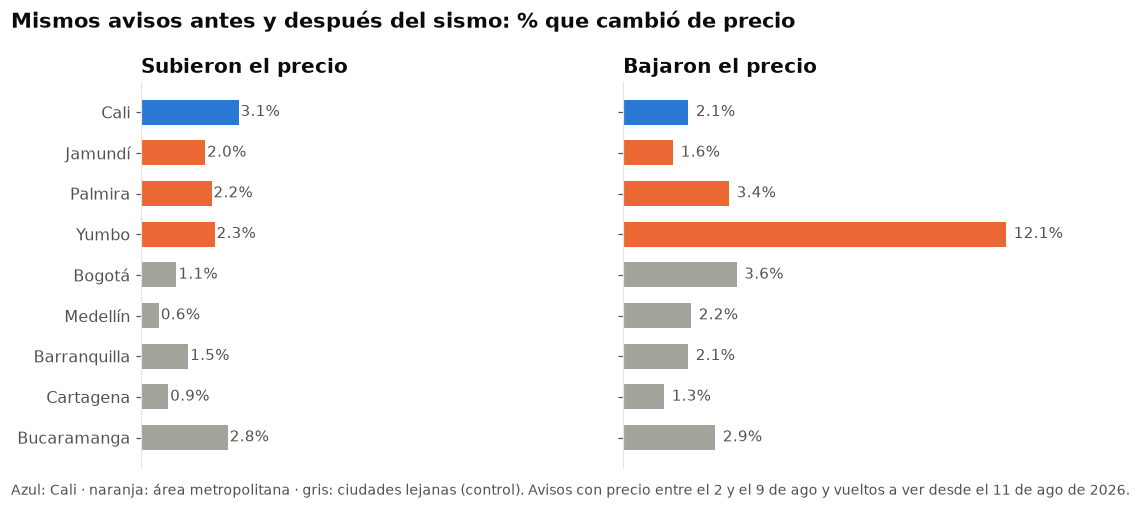

In [6]:
def barras_por_ciudad(ax, serie, titulo, tope):
    s = serie.dropna()
    colores = [COLOR["Cali"] if c == CIUDAD else COLOR["Cercanas"] if c in CERCANAS else COLOR["Control"]
               for c in s.index]
    y = np.arange(len(s))[::-1]
    ax.barh(y, s.values, color=colores, height=0.62)
    ax.set_yticks(y, s.index)
    ax.xaxis.set_major_formatter(pct); ax.grid(axis="y", visible=False)
    for yi, v in zip(y, s.values):
        ax.text(v + s.max() * 0.02, yi, f"{v:.1%}", va="center", fontsize=9.5, color=TINTA2)
    ax.set_xlim(0, tope); ax.set_title(titulo)
    ax.xaxis.set_visible(False); ax.grid(False); ax.spines["bottom"].set_visible(False)

fig, axs = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
tope = por_ciudad[["subió", "bajó"]].max().max() * 1.2      # misma escala en los dos paneles
barras_por_ciudad(axs[0], por_ciudad["subió"], "Subieron el precio", tope)
barras_por_ciudad(axs[1], por_ciudad["bajó"], "Bajaron el precio", tope)
fig.suptitle("Mismos avisos antes y después del sismo: % que cambió de precio",
             x=0.01, ha="left", fontsize=14, fontweight="bold", color=TINTA)
fig.text(0.01, -0.02, "Azul: Cali · naranja: área metropolitana · gris: ciudades lejanas (control). "
         "Avisos con precio entre el 2 y el 9 de ago y vueltos a ver desde el 11 de ago de 2026.",
         fontsize=9, color=TINTA2)
fig.tight_layout(); plt.show()

In [7]:
# De los que sí cambiaron: ¿cuánto subieron o bajaron? (mediana)
cambiaron = par[(par["cambio"] != 0) & (par["grupo"] != "Otras")]
tam = (cambiaron.assign(sentido=np.where(cambiaron["cambio"] > 0, "subió", "bajó"))
       .groupby(["grupo", "sentido"])["cambio"].agg(avisos="size", mediana=lambda x: np.expm1(x.median())))
tam.style.format({"avisos": "{:,.0f}", "mediana": "{:+.1%}"})

## 3. Prueba 2 · ¿Los avisos nuevos salen más caros que lo que había antes?

Que los avisos viejos no suban no descarta que **los nuevos** salgan más caros. Para compararlos sin
mezclar peras con manzanas, cada aviso nuevo se mide contra **inmuebles parecidos que estaban en venta
antes del sismo**: misma ciudad y zona, mismo tipo, estrato y rango de área. Si en su zona no hay al
menos 5 parecidos, se compara a nivel de ciudad.

**Prima** = cuánto más (o menos) pide el aviso nuevo por m² frente a la mediana de sus parecidos de
antes del sismo. Una prima de +5% significa que pide 5% más por m².

> Los avisos nuevos suelen salir algo más caros que los que llevan tiempo publicados (luego rebajan).
> Por eso importa la **diferencia con las ciudades de control**, no la prima sola.

In [8]:
claves_zona = ["Ciudad", "zona", "Tipo_propiedad", "estrato_f", "rango_area"]
claves_ciudad = ["Ciudad", "Tipo_propiedad", "estrato_f", "rango_area"]

def referencia(stock, claves, minimo=5):
    g = stock.groupby(claves, observed=True)["pm2"].agg(["median", "size"])
    return g[g["size"] >= minimo]["median"].rename("ref")

def prima(nuevos, stock):
    """log(precio/m² del aviso ÷ mediana de parecidos en `stock`), por zona o, si no alcanza, por ciudad."""
    r1 = nuevos.join(referencia(stock, claves_zona), on=claves_zona)["ref"]
    r2 = nuevos.join(referencia(stock, claves_ciudad), on=claves_ciudad)["ref"]
    ref = r1.fillna(r2)
    out = nuevos.assign(ref=ref, nivel=np.where(r1.notna(), "zona", np.where(r2.notna(), "ciudad", None)))
    out = out.dropna(subset=["ref"])
    return out.assign(prima=np.log(out["pm2"] / out["ref"]))

# Avisos publicados después del sismo, con su primer precio
nuevos = o[(o["periodo"] == "Después") & (pd.to_datetime(o["first_seen"]) > FECHA_SISMO)]
nuevos = nuevos.sort_values("fecha").groupby("id_inmueble").first().reset_index()
nuevos["semana"] = pd.to_datetime(nuevos["fecha"]).dt.to_period("W-SUN").dt.start_time

pn = prima(nuevos, antes.reset_index())
print(f"{len(nuevos):,} avisos nuevos después del sismo · {len(pn):,} con parecidos de antes "
      f"({(pn['nivel'] == 'zona').mean():.0%} comparados en su zona)")

63,459 avisos nuevos después del sismo · 61,649 con parecidos de antes (45% comparados en su zona)


In [9]:
def mediana_ic(x, n=1000):
    x = np.asarray(x)
    b = [np.median(rng.choice(x, len(x))) for _ in range(n)]
    return pd.Series({"avisos": len(x), "prima": np.expm1(np.median(x)),
                      "IC90% bajo": np.expm1(np.percentile(b, 5)), "IC90% alto": np.expm1(np.percentile(b, 95))})

prima_grupo = pn[pn["grupo"] != "Otras"].groupby("grupo")["prima"].apply(mediana_ic).unstack()
c, k = pn[pn["grupo"] == "Cali"]["prima"], pn[pn["grupo"] == "Control"]["prima"]
d, lo, hi = ic_diferencia(c, k, np.median)
prima_grupo.loc["Cali − control"] = [np.nan, np.expm1(d), np.expm1(lo), np.expm1(hi)]
prima_grupo.style.format({"avisos": "{:,.0f}", "prima": "{:+.1%}", "IC90% bajo": "{:+.1%}",
                          "IC90% alto": "{:+.1%}"}, na_rep="")

,avisos,prima,IC90% bajo,IC90% alto
grupo,,,,
Cali,"4,371",-0.1%,-0.8%,+0.4%
Cercanas,"1,192",+2.2%,+1.1%,+3.3%
Control,"37,105",+1.7%,+1.4%,+2.0%
Cali − control,,-1.7%,-2.5%,-1.2%


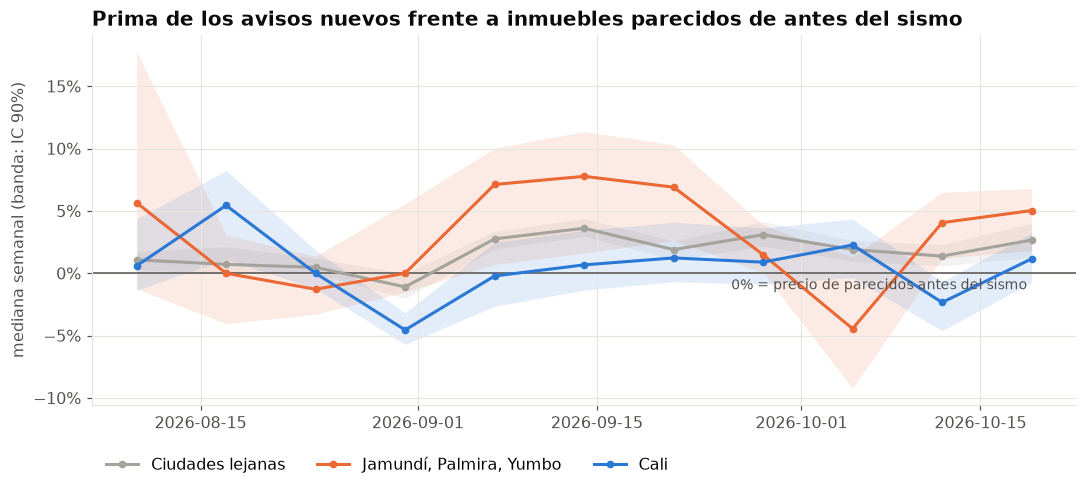

In [10]:
psem = pn[pn["grupo"] != "Otras"]
psem = psem[psem.groupby(["grupo", "semana"])["prima"].transform("size") >= 30]   # semanas con datos suficientes
sem = psem.groupby(["grupo", "semana"])["prima"].apply(lambda x: mediana_ic(x, 400)).unstack()

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.axhline(0, color=TINTA2, linewidth=1)
ax.text(sem.index.get_level_values("semana").max(), -0.004, "0% = precio de parecidos antes del sismo ",
        fontsize=9, color=TINTA2, va="top", ha="right")
for g in ["Control", "Cercanas", "Cali"]:
    if g not in sem.index.get_level_values("grupo"):
        continue
    s = sem.loc[g]
    ax.fill_between(s.index, s["IC90% bajo"], s["IC90% alto"], color=COLOR[g], alpha=0.13, linewidth=0)
    ax.plot(s.index, s["prima"], color=COLOR[g], linewidth=2, marker="o", markersize=4,
            label={"Cali": "Cali", "Cercanas": "Jamundí, Palmira, Yumbo", "Control": "Ciudades lejanas"}[g])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_title("Prima de los avisos nuevos frente a inmuebles parecidos de antes del sismo")
ax.set_ylabel("mediana semanal (banda: IC 90%)")
ax.legend(loc="upper left", ncol=3, bbox_to_anchor=(0, -0.1))
fig.tight_layout(); plt.show()

**Comprobación:** en agosto el scraper todavía estaba descubriendo avisos que ya existían (el modo
incremental arrancó el 8 de agosto), así que no todo lo "nuevo" de esas semanas era nuevo de verdad.
Repetimos la comparación solo con avisos aparecidos desde el 1 de septiembre.

In [11]:
sep = pn[pd.to_datetime(pn["fecha"]) >= "2026-09-01"]
c, k = sep[sep["grupo"] == "Cali"]["prima"], sep[sep["grupo"] == "Control"]["prima"]
d, lo, hi = ic_diferencia(c, k, np.median)
print(f"Desde septiembre · Cali {np.expm1(np.median(c)):+.1%} ({len(c):,} avisos) · "
      f"control {np.expm1(np.median(k)):+.1%} ({len(k):,}) · "
      f"diferencia {np.expm1(d):+.1%} (IC 90%: {np.expm1(lo):+.1%} a {np.expm1(hi):+.1%})")

Desde septiembre · Cali -0.6% (3,275 avisos) · control +2.1% (25,697) · diferencia -2.6% (IC 90%: -3.4% a -1.9%)


### ¿Y cuánto suben los precios en un año normal?

Para poner la prima en contexto, la misma comparación entre **julio de 2025** y la semana **antes del
sismo**: cuánto más pedían los avisos de agosto de 2026 frente a sus parecidos de un año antes.

In [12]:
stock25 = ultima(o[o["periodo"] == "Julio 2025"]).reset_index()
anual = prima(antes.reset_index(), stock25)
tendencia = anual[anual["grupo"] != "Otras"].groupby("grupo")["prima"].apply(mediana_ic).unstack()
tendencia.style.format({"avisos": "{:,.0f}", "prima": "{:+.1%}", "IC90% bajo": "{:+.1%}", "IC90% alto": "{:+.1%}"})

,avisos,prima,IC90% bajo,IC90% alto
grupo,,,,
Cali,"2,138",+8.8%,+7.3%,+10.1%
Cercanas,"1,910",+0.9%,+0.0%,+1.8%
Control,"12,386",+8.4%,+7.8%,+8.9%


## 4. Prueba 3 · ¿Salió más oferta a la venta en Cali?

Si el sismo hubiera empujado a mucha gente a vender, Cali tendría **una parte mayor** de los avisos
nuevos que antes. Se mide como la participación de Cali en los avisos nuevos de Cali + ciudades de
control, frente a su participación en lo que había publicado antes del sismo y en julio de 2025.

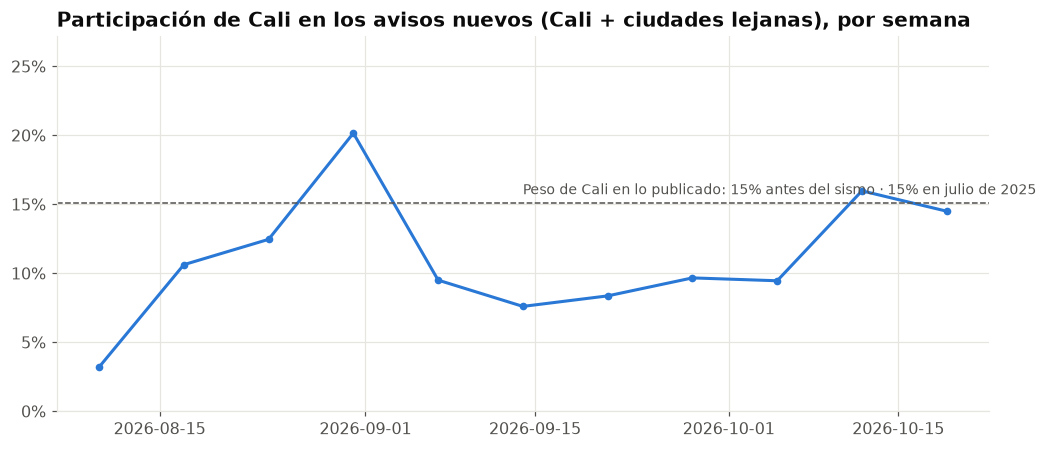

,avisos nuevos Cali,participación
semana,,
2026-08-10 00:00:00,143,3.2%
2026-08-17 00:00:00,293,10.6%
2026-08-24 00:00:00,664,12.5%
2026-08-31 00:00:00,874,20.2%
2026-09-07 00:00:00,420,9.5%
2026-09-14 00:00:00,305,7.6%
2026-09-21 00:00:00,316,8.4%
2026-09-28 00:00:00,365,9.7%
2026-10-05 00:00:00,311,9.5%


In [13]:
nuevos_sem = nuevos[nuevos["grupo"].isin(["Cali", "Control"])].groupby(["semana", "grupo"]).size().unstack()
part = nuevos_sem["Cali"] / nuevos_sem.sum(axis=1)
ref_antes = (antes["grupo"] == "Cali").sum() / antes["grupo"].isin(["Cali", "Control"]).sum()
ref_25 = (stock25["grupo"] == "Cali").sum() / stock25["grupo"].isin(["Cali", "Control"]).sum()

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(part.index, part.values, color=COLOR["Cali"], linewidth=2, marker="o", markersize=4)
ax.axhline(ref_antes, color=TINTA2, linewidth=1, linestyle="--")
ax.text(part.index[len(part) // 2], ref_antes + 0.004, f"Peso de Cali en lo publicado: {ref_antes:.0%} antes del sismo · "
        f"{ref_25:.0%} en julio de 2025", fontsize=9, color=TINTA2, va="bottom")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0)); ax.set_ylim(0, max(part.max(), ref_antes) * 1.35)
ax.set_title("Participación de Cali en los avisos nuevos (Cali + ciudades lejanas), por semana")
fig.tight_layout(); plt.show()
pd.DataFrame({"avisos nuevos Cali": nuevos_sem["Cali"], "participación": part}).style.format({"participación": "{:.1%}"})

## 5. ¿Dónde y en qué tipo de vivienda? (solo Cali)

Si el sismo hubiera golpeado más a ciertas zonas, ahí se vería una prima distinta. Abajo, la prima de
los avisos nuevos **por comuna**, y luego por tipo y estrato. Si sabes qué zonas fueron más afectadas,
este es el lugar para contrastarlo.

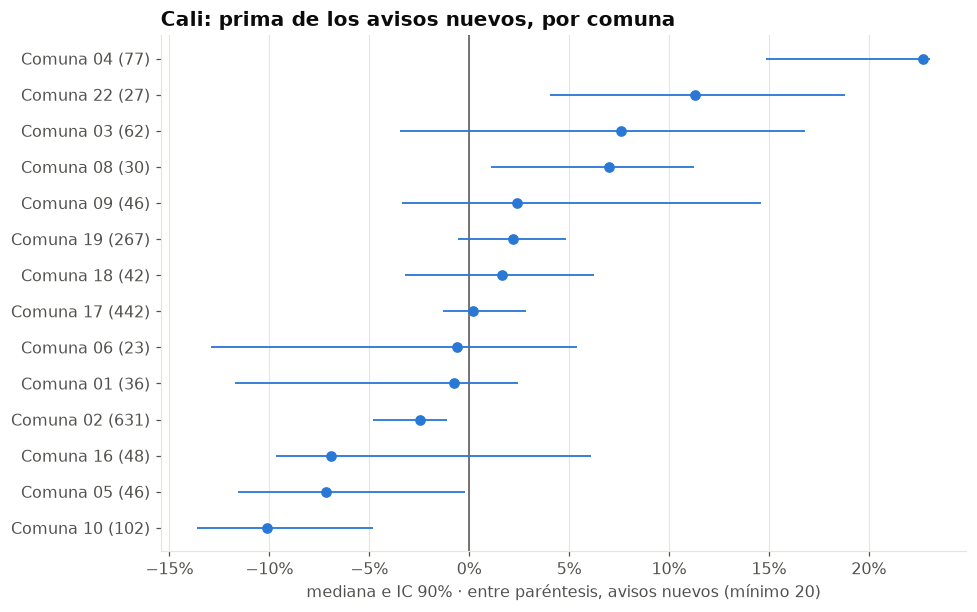

In [14]:
cali_pn = pn[pn["grupo"] == "Cali"]
con_comuna = cali_pn.dropna(subset=["comuna"])
con_comuna = con_comuna[con_comuna.groupby("comuna")["prima"].transform("size") >= 20]
por_comuna = (con_comuna.groupby("comuna")["prima"].apply(lambda x: mediana_ic(x, 500))
              .unstack().sort_values("prima"))

fig, ax = plt.subplots(figsize=(9, 0.32 * len(por_comuna) + 1.2))
y = np.arange(len(por_comuna))
ax.axvline(0, color=TINTA2, linewidth=1)
ax.errorbar(por_comuna["prima"], y, xerr=[por_comuna["prima"] - por_comuna["IC90% bajo"],
            por_comuna["IC90% alto"] - por_comuna["prima"]], fmt="o", color=COLOR["Cali"],
            ecolor=COLOR["Cali"], elinewidth=1.2, capsize=0, markersize=6)
ax.set_yticks(y, [f"Comuna {c} ({n:.0f})" for c, n in zip(por_comuna.index, por_comuna["avisos"])])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0)); ax.grid(axis="y", visible=False)
ax.set_title("Cali: prima de los avisos nuevos, por comuna")
ax.set_xlabel("mediana e IC 90% · entre paréntesis, avisos nuevos (mínimo 20)")
fig.tight_layout(); plt.show()

In [15]:
def tabla_prima(col):
    t = cali_pn.groupby(col, observed=True)["prima"].apply(lambda x: mediana_ic(x, 500)).unstack()
    return t.style.format({"avisos": "{:,.0f}", "prima": "{:+.1%}", "IC90% bajo": "{:+.1%}", "IC90% alto": "{:+.1%}"})

display(tabla_prima("Tipo_propiedad"))
display(tabla_prima("estrato_f"))

,avisos,prima,IC90% bajo,IC90% alto
Tipo_propiedad,,,,
Apartaestudio,96,+1.0%,-6.4%,+7.6%
Apartamento,"2,769",+0.2%,-0.5%,+0.8%
Casa,"1,506",-1.2%,-2.9%,+0.0%


,avisos,prima,IC90% bajo,IC90% alto
estrato_f,,,,
2,90,-0.1%,-6.2%,+3.6%
3,545,+3.3%,+1.2%,+6.1%
4,"1,389",-0.9%,-1.4%,+0.0%
5,"1,270",+0.7%,-0.5%,+2.5%
6,"1,036",-1.4%,-3.5%,+0.2%
sin dato,41,-19.5%,-25.9%,-2.3%


## 6. Qué dicen (y qué no) los datos

Cifras con datos al **24 de octubre de 2026**. Si vuelves a ejecutar con `REHACER_PANEL = True`, los
números se actualizan y estas conclusiones pueden quedar desfasadas.

**Veredicto: en el mercado de venta de Cali, los datos no muestran que los precios se hayan disparado
después del sismo, ni que los vendedores se hayan aprovechado de forma generalizada.**

| Pregunta | Qué muestran los datos |
|---|---|
| ¿Subieron el precio de lo que ya tenían publicado? | **Casi nadie.** De 581 avisos de Cali vistos antes y después, el 94,8% siguió con el mismo precio. Subió el 3,1% (18 avisos, mediana +5,2%) y bajó el 2,1%. En Cali subieron algo más que en las ciudades lejanas (+1,6 puntos, IC 90%: +0,5 a +2,9), pero el cambio promedio de precio es prácticamente cero (+0,1%). |
| ¿Los avisos nuevos salen más caros? | **No.** Frente a inmuebles parecidos de antes del sismo, los avisos nuevos de Cali piden lo mismo (−0,1%). En las ciudades lejanas piden un 1,7% más. Cali queda **1,7% por debajo** del control (IC 90%: −2,5% a −1,2%), y desde septiembre la brecha es de −2,6%. |
| ¿Venía Cali subiendo distinto? | **No.** Entre julio de 2025 y la semana antes del sismo, los precios pedidos subieron +8,8% en Cali y +8,4% en las ciudades lejanas: el mismo ritmo. |
| ¿Salió más oferta? | **No de forma sostenida.** Hubo un pico a fines de agosto (20% de los avisos nuevos, frente a un peso normal del 15%), pero en septiembre y comienzos de octubre Cali aportó menos de lo habitual (8–10%). Esta medida es la más frágil: en agosto la cobertura del scraper estaba cambiando. |
| ¿Hay zonas distintas? | **Sí, y vale la pena mirarlas.** Los avisos nuevos de la comuna 4 piden un 23% más que sus parecidos de antes (77 avisos), la 22 un 11% y la 3 y la 8 alrededor de un 7–8%; en cambio, la 10 (−10%) y la 5 (−7%) piden menos. Con 14 comunas, alguna diferencia extrema puede salir por azar: conviene contrastarlas con dónde hubo daños. |

**Lo que estos datos no pueden responder:**

- **Arriendos.** Es donde más se escucha que "se dispararon" (familias desplazadas buscando dónde vivir)
  y el scraper solo recolecta ventas. Sería el siguiente análisis natural.
- **Precios de cierre.** Son precios pedidos; un mercado puede negociar distinto aunque los avisos no cambien.
- **Reparaciones y materiales.** Mano de obra, materiales o seguros no están en estos datos.
- **Línea base corta.** Antes del sismo hay solo una semana de 2026 (2–9 de agosto), más la foto de julio
  de 2025.